# Dependencies

In [1]:
import neo
import numpy as np
import os
import pandas as pd
import matplotlib.pylab as plt
import tqdm
from tqdm import tqdm
import numpy as np
import bisect

# Functions

In [59]:
def check_invert(arr):                 # a function that checks if an AP is 'inverted', defined as the functions outline. 
    #  a spike waveform array          # this is optional, but will make APs all look the 'same' direction which can be useful for finding spike-width
    global min_diff, max_diff
    mean = np.mean(arr) #get mean
    mini = np.min(arr) #get min
    maxi = np.max(arr) #get max
    min_diff = abs(mini-mean) # get diffs between min and max against mean
    max_diff = abs(maxi-mean)
    if min_diff > max_diff:  #if min-mean > max-mean, then signal is considered inverted
        inversion=-1  #set inversion to -1 to multiply the waveform and flip it
    else:
        inversion=1

    return inversion


#read and organize all cluster txt files from a kilosort folder
# put all in a single df


def read_clustersTimes(spath):  #reads cluster time information
    #input: patrh to folder with cluster.txt files
    import re  #import library to parse numbers from text
    files = []
    for i in os.listdir(spath):  #check folder for correct files, when found store its name
        if 'cluster' in i and '.txt' in i:
            files.append(i)

    dfs = []

    for i in range(len(files)): #loop through each found file
        tmp = pd.read_csv(os.path.join(spath, files[i]), header=None) #read it as csv
        tmp = tmp.rename(columns={0:'spike_times'}) 
        tmp['ID_long'] = files[i]
        tmp['cluster'] = int(re.findall(r'\d+',files[i])[0])  #add cluster name as clolumn
        dfs.append(tmp) #append df rto list

    return pd.concat(dfs).reset_index(drop=True) #return a master df with all of the cluster's spiketimes




def searchNextract_spikeWaveforms(data, stimes_df, tarr, cluster):  # searches and extracts spike waveforms from a .dat file
    #inputs:
        #data: this is the import .dat file with all analog channels 
        #stimes_df: a df with cluster and spike-times info
        #tarr this is an array of "true-bin time", essentially each cell's values are a mulitple of the resolution (1/30000)


    def get_closest_index(time, large_array):  #function to get the closest index of the spike onset

        # Convert the time to the corresponding index in the large array
        target_index = time
        insert_pos = bisect.bisect_left(large_array, target_index) #do a binary-based search for the spike (VERY FAST)
        
        
        if insert_pos == 0:# If the insertion point is at the start of the array
            return 0
       
        if insert_pos == len(large_array): # If the insertion point is at the end of the array
            return len(large_array) - 1
        
        
        before = large_array[insert_pos - 1]# Check the two closest positions: before and after the insertion point
        after = large_array[insert_pos]
        
        
        if abs(before - target_index) <= abs(after - target_index): # Return the closest index based on absolute distance
            return insert_pos - 1
        else:
            return insert_pos

    def get_sample_indices(event_times, large_array): #get sample indices by looping can calling above fiunction to fo the heavy lifting
        indices = []
        for event_time in event_times:
            index = get_closest_index(event_time, large_array)
            indices.append(index)
        return np.array(indices)
    


    sr = 30000
    resolution = 1/sr


    targets = np.array(stimes_df[stimes_df.cluster==cluster].reset_index(drop=True).spike_times)       #get cluster specific spike-times
    #chan =    #get channel from cluster_info.tsv for comprehensive tracking of data


    indices = get_sample_indices(targets, tarr)
    #print(indices)  # Indices that correspond to event times in the large array

    waveforms = []
    for i in tqdm(range(len(indices)), desc='extarcting spike waveforms'): #loop and get windowed spike waveforms
        waveforms.append(data[indices[i]-15:indices[i]+25])


    return waveforms


def make_timeBinArray(sr, length):   #make the time array of equal time-bins based on samplig rate for crossreference
    resolution = 1/sr
    return [resolution*i for i in range(length)]



def plot_Cluster(cluster, std_fac, soft_check=True, inversion=True):
    global wave_label, diff
    indi = np.where(cluster==np.array(cluster_id))[0][0]
    if inversion:
        check_invert(avg_waves[indi])
        if soft_check:
            diff = abs(max(avg_waves[indi])-min(avg_waves[indi]))
            if diff < 5:
                plt.plot(avg_waves[indi]*check_invert(avg_waves[indi]), c='r', label='likely bad unit')
                plt.fill_between(list(range(len(avg_waves[indi]))), (avg_waves[indi]*check_invert(avg_waves[indi])-std_waves[indi]*std_fac), (avg_waves[indi]*check_invert(avg_waves[indi])+std_waves[indi]*std_fac), color='b', alpha=.3)
                plt.title('Cluster '+str(cluster)+' in chan '+str(chani[indi]))
                wave_label=0
                plt.legend()
                plt.show()
            else:
                plt.plot(avg_waves[indi]*check_invert(avg_waves[indi]), c='b', label='likely good unit')
                plt.fill_between(list(range(len(avg_waves[indi]))), (avg_waves[indi]*check_invert(avg_waves[indi])-std_waves[indi]*std_fac), (avg_waves[indi]*check_invert(avg_waves[indi])+std_waves[indi]*std_fac), color='b', alpha=.3)
                plt.title('Cluster '+str(cluster)+' in chan '+str(chani[indi]))
                wave_label=1
                plt.legend()
                plt.show()
        else:
            plt.plot(avg_waves[indi]*check_invert(avg_waves[indi]), c='b')
            plt.fill_between(list(range(len(avg_waves[indi]*check_invert(avg_waves[indi])))), (avg_waves[indi]*check_invert(avg_waves[indi])-std_waves[indi]*std_fac), (avg_waves[indi]*check_invert(avg_waves[indi])+std_waves[indi]*std_fac), color='b', alpha=.3)
            plt.title('Cluster '+str(cluster)+' in chan '+str(chani[indi]))
            plt.legend()
            plt.show()
    else:
        if soft_check:
            diff = abs(max(avg_waves[indi])-min(avg_waves[indi]))
            if diff < 5:
                plt.plot(avg_waves[indi], c='r', label='likely bad unit')
                plt.fill_between(list(range(len(avg_waves[indi]))), (avg_waves[indi]-std_waves[indi]*std_fac), (avg_waves[indi]+std_waves[indi]*std_fac), color='b', alpha=.3)
                plt.title('Cluster '+str(cluster)+' in chan '+str(chani[indi]))
                wave_label=0
                plt.legend()
                plt.show()
            else:
                plt.plot(avg_waves[indi], c='b', label='likely good unit')
                plt.fill_between(list(range(len(avg_waves[indi]))), (avg_waves[indi]-std_waves[indi]*std_fac), (avg_waves[indi]+std_waves[indi]*std_fac), color='b', alpha=.3)
                plt.title('Cluster '+str(cluster)+' in chan '+str(chani[indi]))
                wave_label=1
                plt.legend()
                plt.show()
        else:
            plt.plot(avg_waves[indi], c='b')
            plt.fill_between(list(range(len(avg_waves[indi]))), (avg_waves[indi]-std_waves[indi]*std_fac), (avg_waves[indi]+std_waves[indi]*std_fac), color='b', alpha=.3)
            plt.title('Cluster '+str(cluster)+' in chan '+str(chani[indi]))
            plt.legend()
            plt.show()
    return wave_label


def spike_aligner(waveforms, align_reference = 'minimum', plot=True):
    ## inputs: 
    # waveforms: 2d array, where each row contain waveform data
    # align_reference: minimum or maximum, determine what is the reference agaisnt which to align
    # plot: if True, plot the original and the aligned data for comparison

    # output: aligned waveforms in same input format
    if plot:
        fig, axs = plt.subplots(1, 2, figsize=(14, 6))
        arr = waveforms
        for i in range(len(arr)):
            axs[0].plot(arr[i])
        axs[0].set_title('original')

    for i, w in enumerate(waveforms):  #get an idea of required shifts in the data
        shift = np.random.randint(-10, 10)
        waveforms[i] = np.roll(w, shift)

    match align_reference:
        case 'minimum':
            max_indices = [np.argmin(w) for w in waveforms]
        case 'maximum':
            max_indices = [np.argmax(w) for w in waveforms]
        case _:
            print('Exiting from function without processing.. Please choose minimum or maximum for the align_reference value')

    # determine where to shift from
    ref_index = len(waveforms[0]) // 2

    # Step 3: Compute shifts
    shifts = [ref_index - idx for idx in max_indices]  #computer required shifts for each waveform

    if plot:
        
        X = [np.roll(w, s) for w, s in zip(waveforms, shifts)]
        for i in range(len(X)):
            axs[1].plot(X[i], c='r', alpha=.5)
        axs[1].set_title('aligned')

    return [np.roll(w, s) for w, s in zip(waveforms, shifts)]

# Single File Example
## this method can be used to extract, differentiate, and explore single unit detected by Kilosort
### The code first loads the dat ephys file onto RAM (can be intensive..) using neo library
### NOTE: a dataframe with time stamps for each cluster/unit is required to run this code. the DF should have one column for times and another for clusters
### The timestamps are then used to find and dissect-out single-unit waveforms, from which an average waveform is derived for processing
### other functions exist to plot and cluster units based on shape or things like P2P

In [ ]:
#load the dat file


fpath = r"Z:\GREEN7475\GREEN7475_zfcan\zfcan1_2025-07-28_17-23-04\Record Node 101\experiment1\recording1"


reader = neo.io.OpenEphysBinaryIO(fpath)
block = reader.read_block()
segment = block.segments[0]
sig = segment.analogsignals[0]
data_array = sig.magnitude  # This gives the signal values as a numpy array.. not sure if required.. 

In [ ]:
#load the df with spike times and cluster info
spath = r'Z:\GREEN7475\GREEN7475_zfcan\zfcan1_2025-07-28_17-23-04\kilosort4'
stimes_df = read_clustersTimes(spath)


In [ ]:
#load in clkuster info for looping information (i.e. search cnhannel to process based on cluster ID)
# this will allow to determine which channel to search for a given cluster

clus_info = pd.read_csv(r"Z:\GREEN7475\GREEN7475_zfcan\zfcan1_2025-07-28_17-23-04\kilosort4\cluster_info.tsv", sep='\t')
clus_info.iloc[:2]

In [ ]:
# MAIN EXTRACTION LOOP


tarr = make_timeBinArray(sr=30000, length = len(data_array[:][:,1] )) # for a given channel (all should be equal in same recording), get length of data

avg_waves = []
std_waves = []
cluster_id = []
chani = []


for cluster in stimes_df.cluster.unique():
    chan = int(clus_info[clus_info.cluster_id==58].ch)
    waveforms = searchNextract_spikeWaveforms(data_array[:][:,chan], stimes_df, tarr, cluster=cluster)
    try:
        avg_waves.append(np.mean(waveforms, axis=0))  #there is an underlying issue to this, will have to figure out.. sometimes an array is empty
        std_waves.append(np.std(waveforms, axis=0))
    except:
        avg_waves.append(np.mean(waveforms[1:], axis=0))
        std_waves.append(np.std(waveforms[1:], axis=0))
    cluster_id.append(cluster)
    chani.append(chan)

In [ ]:
# quick plot/derivation of label

ind_out = []

soft_check=True
k=0
for cl in cluster_id[:4]:

    wave_label = plot_Cluster(cluster=cl, std_fac=.1, soft_check=soft_check, inversion=False)
    if soft_check:
        if wave_label==0:
            ind_out.append(cl)
    k+=1

In [ ]:


#plot each lcluster average with a error band

from scipy.stats import zscore
ss = [1, -5]
col = ['b', 'r']
label = ['Narrow', 'Wide']
fac=.05
for i, s in enumerate(ss):
    wave = zscore(avg_waves[s])
    plt.plot(wave, c=col[i])
    plt.fill_between(range(len(avg_waves[s])),wave-std_waves[s]*fac,wave+std_waves[s]*fac, alpha=.3, color=col[i], label=label[i])
plt.legend()
plt.ylabel('Z-score(mV)', fontsize=18)
plt.xlabel('Time (ms)', fontsize=18)

xs = []
ogxs = []
for i in range(11):
    xs.append(round(i*4*.005*10, 2))
    ogxs.append(i*4)


plt.xticks(ogxs, xs)
plt.show()

In [ ]:
ind_out = []

soft_check=True
k=0
for cl in cluster_id:

    plot_Cluster(cluster=cl, std_fac=500, soft_check=soft_check, inversion = True)
    if soft_check:
        if wave_label==0:
            ind_out.append(cl)
    k+=1

In [ ]:
for cl in cluster_id:
    if cl in ind_out:
        continue
    plot_Cluster(cluster=cl, std_fac=5, soft_check=True, inversion=True)

In [ ]:

#zscore waveforms to plot in same space

from scipy.stats import zscore
zwaves = []  #and cleaned
for i in range(len(avg_waves)):
    if cluster_id[i] in ind_out:
        continue
    
    zwaves.append(zscore(avg_waves[i]*check_invert(avg_waves[i])))


In [ ]:
#plot zwaves

for i in range(len(zwaves)):
    plt.plot(zwaves[0])
plt.axhline(np.mean(zwaves[0]+np.std(zwaves[0])*1))
plt.show()


In [ ]:
#compute amplitude and the P2P

tdiff = []
amp = []
for i in range(len(zwaves)):
    maxi = np.argmax(zwaves[i])
    mini = np.argmin(zwaves[i][:maxi])
    tdiff.append(abs(maxi-mini))
    amp.append(abs(np.max(zwaves[i])-np.min(zwaves[i])))
plt.hist(tdiff)
plt.show()
plt.scatter(tdiff, amp)
plt.xlabel('p2p difference')
plt.ylabel('amplitude')

In [ ]:
#optional, project waveforms into PC space


from sklearn.decomposition import PCA
import seaborn as sns
pca = PCA(n_components=3)

tra = pca.fit_transform(zwaves)

pcdf = pd.DataFrame({'PC1':tra[:,0], 'PC2':tra[:,1], 'PC3':tra[:,2], 'tdiff':tdiff})
sns.scatterplot(x='PC1', y='PC2',hue='tdiff', data=pcdf)

In [ ]:
#plot all waves in same plot
for i in range(len(avg_waves)):
    plt.plot(avg_waves[i])

# Batch spike reader
### similar as the single file case, but batched
### note how the relevant files are being searched.. the folder path should be set to a folder that itself contains OpenEphys project/subject folders
###             these project folders can contain multiple recordings, in addition to multiple record nodes (which you should keep in mind, in case some should be skipped!!)
### the resulting spike waveforms, for each recording, should be stored within the respective Record Node folder!!

In [ ]:
import neo
import numpy as np
import os
import pandas as pd
import matplotlib.pylab as plt
import tqdm
from tqdm import tqdm

import re
import seaborn as sns
import gc

In [ ]:
# redudnant redefinition of functions


def check_invert(arr):                 # a function that checks if an AP is 'inverted', defined as the functions outline. 
    #  a spike waveform array          # this is optional, but will make APs all look the 'same' direction which can be useful for finding spike-width
    global min_diff, max_diff
    mean = np.mean(arr) #get mean
    mini = np.min(arr) #get min
    maxi = np.max(arr) #get max
    min_diff = abs(mini-mean) # get diffs between min and max against mean
    max_diff = abs(maxi-mean)
    if min_diff > max_diff:  #if min-mean > max-mean, then signal is considered inverted
        inversion=-1  #set inversion to -1 to multiply the waveform and flip it
    else:
        inversion=1

    return inversion
#read and organize all cluster txt files from a kilosort folder
# put all in a single df


def read_clustersTimes(spath):  #reads cluster time information
    #input: patrh to folder with cluster.txt files
    import re  #import library to parse numbers from text
    files = []
    for i in os.listdir(spath):  #check folder for correct files, when found store its name
        if 'cluster' in i and '.txt' in i:
            files.append(i)

    dfs = []

    for i in range(len(files)): #loop through each found file
        tmp = pd.read_csv(os.path.join(spath, files[i]), header=None) #read it as csv
        tmp = tmp.rename(columns={0:'spike_times'}) 
        tmp['ID_long'] = files[i]
        tmp['cluster'] = int(re.findall(r'\d+',files[i])[0])  #add cluster name as clolumn
        dfs.append(tmp) #append df rto list

    return pd.concat(dfs).reset_index(drop=True) #return a master df with all of the cluster's spiketimes

import numpy as np
import bisect


def searchNextract_spikeWaveforms(data, stimes_df, tarr, cluster):  # searches and extracts spike waveforms from a .dat file
    #inputs:
        #data: this is the import .dat file with all analog channels 
        #stimes_df: a df with cluster and spike-times info
        #tarr this is an array of "true-bin time", essentially each cell's values are a mulitple of the resolution (1/30000)


    def get_closest_index(time, large_array):  #function to get the closest index of the spike onset

        # Convert the time to the corresponding index in the large array
        target_index = time
        insert_pos = bisect.bisect_left(large_array, target_index) #do a binary-based search for the spike (VERY FAST)
        
        
        if insert_pos == 0:# If the insertion point is at the start of the array
            return 0
       
        if insert_pos == len(large_array): # If the insertion point is at the end of the array
            return len(large_array) - 1
        
        
        before = large_array[insert_pos - 1]# Check the two closest positions: before and after the insertion point
        after = large_array[insert_pos]
        
        
        if abs(before - target_index) <= abs(after - target_index): # Return the closest index based on absolute distance
            return insert_pos - 1
        else:
            return insert_pos

    def get_sample_indices(event_times, large_array): #get sample indices by looping can calling above fiunction to fo the heavy lifting
        indices = []
        for event_time in event_times:
            index = get_closest_index(event_time, large_array)
            indices.append(index)
        return np.array(indices)
    


    sr = 30000
    resolution = 1/sr


    targets = np.array(stimes_df[stimes_df.cluster==cluster].reset_index(drop=True).spike_times)       #get cluster specific spike-times
    #chan =    #get channel from cluster_info.tsv for comprehensive tracking of data


    indices = get_sample_indices(targets, tarr)
    #print(indices)  # Indices that correspond to event times in the large array

    waveforms = []
    for i in tqdm(range(len(indices)), desc='extarcting spike waveforms'): #loop and get windowed spike waveforms
        waveforms.append(data[indices[i]-15:indices[i]+25])


    return waveforms
def make_timeBinArray(sr, length):   #make the time array of equal time-bins based on samplig rate for crossreference
    resolution = 1/sr
    return [resolution*i for i in range(length)]

In [ ]:
#not ready for primetime.. there is a path issue, I am missing one of the folder-layers (specifically the one for the project name)


mpath = r'M:\AudObj_post_kilo\done'  #chnage to desired directory, should contain folders of recording sessions!

folders = [f for f in os.listdir(mpath) if os.path.isdir(os.path.join(mpath, f))] #gte folder names

folders = ['gn065']

#folders = folders[0:2]  #for testing.. for a subset and not letting it run 

for idx in range(len(folders)):  #loop through session recordings
    stimes_df=None  # check to ensure correct stimes_df is employed
    proj_path = os.path.join(mpath, folders[idx])  #get path where porjects are located

    #loop through different project folders embedded in the session
    for proj in os.listdir(proj_path):
        if 'tu' in proj or 'zf' in proj:      #HERE, you can filter out which projects you want/dont want to run through by using key substrings
            print('skipping '+proj)
            continue
        rec1_path = os.path.join(proj_path, proj, os.listdir(os.path.join(proj_path, proj))[0]  ,'experiment1', 'recording1') #recording path, necessary for neo package to read dat file
        spath = os.path.join(proj_path, proj, os.listdir(os.path.join(proj_path, proj))[0]  ,'experiment1', 'recording1', 'continuous', 'Rhythm_FPGA-100.0', 'kilosort4')
        clus_info_path = os.path.join(proj_path, proj, os.listdir(os.path.join(proj_path, proj))[0]  ,'experiment1', 'recording1', 'continuous', 'Rhythm_FPGA-100.0', 'kilosort4')
        clus_info_path = clus_info_path+'\\cluster_info.tsv'  #path for the tsv file with all clsuter info stuff

        try:
            clus_info = pd.read_csv(clus_info_path, sep='\t')  #this try/catch was really to address an issue with my folder (one has not been 'phyed')
        except:
            continue
        print('processing '+proj_path+'__'+proj+'; now loding the data') 

        reader = neo.io.OpenEphysBinaryIO(rec1_path)  #block to read the dat file (will use a lot of RAM!)
        block = reader.read_block()
        segment = block.segments[0]
        sig = segment.analogsignals[0]
        data_array = sig.magnitude  # This gives the signal values as a numpy array.. not sure if required.. 


        # MAIN EXTRACTION LOOP

        def make_timeBinArray(sr, length):   #make the time array of equal time-bins based on samplig rate for crossreference
            resolution = 1/sr
            return [resolution*i for i in range(length)]


        tarr = make_timeBinArray(sr=30000, length = len(data_array[:][:,1])) # for a given channel (all should be equal in same recording), get length of data

        avg_waves = []
        std_waves = []
        cluster_id = []
        chani = []

        stimes_df = read_clustersTimes(spath)  #this will read ALL the cluster time stampts.. This means that one has to have already made all of the text files (Luke's code takes care of this)

        for cluster in stimes_df.cluster.unique(): #loop through each cluster (that had associated text file)
            chan = int(clus_info[clus_info.cluster_id==cluster].ch)  #get channel number associated with cluster
            waveforms = searchNextract_spikeWaveforms(data_array[:][:,chan], stimes_df, tarr, cluster=cluster)  # use bisect algorithm to extract all waveforms for the unit/cluster
            waveforms = [xs for xs in waveforms if len(xs) == 40]  # get a 40 bin window of the clusters (make sure it is 40 bins)
            #try:
            #    avg_waves.append(np.mean(waveforms, axis=0))  #there is an underlying issue to this, will have to figure out.. sometimes an array is empty
            #    std_waves.append(np.std(waveforms, axis=0))
            #except:
            #    avg_waves.append(np.mean(waveforms[1:], axis=0))
            #    std_waves.append(np.std(waveforms[1:], axis=0))

            #waveforms = [xs for xs in waveforms if len(xs) == 40]

            avg_waves.append(np.mean(waveforms, axis=0))  #get mean of cluster's waveforms
            std_waves.append(np.std(waveforms, axis=0))   #get SD of cluster's waveforms

            cluster_id.append(cluster)   #keep trrasck of cluster_id
            chani.append(chan)           #keep track of channel of origin
        tmp = pd.DataFrame({'clus_id':cluster_id})  #store info
        tmp['avg_arrs'] = [x for x in avg_waves]  #store avg_waveforms for each cluster

        print('saving unit df for '+proj_path)
        save_path = os.path.join(proj_path, proj, os.listdir(os.path.join(proj_path, proj))[0]) + '\\unit_waves.pkl'  
                    
        tmp.to_pickle(save_path)   #save the df with relevant info

        del reader
        del block
        del segment
        del sig
        del data_array
        del waveforms
        del avg_waves
        del std_waves
        del tarr
        import gc
        gc.collect()  #delete generated and loaded data, then clear/release RAM  (check your task manager, RAM should ramp up/down periodically).. IF NOT, stop the code and check why

    

In [3]:
# this will be made cleaner.........
# but, for now, I am manually loading all the files and then concatenating them


lh_91925_ao1 = pd.read_pickle(r"M:\audObj2kilo\9-19-25_lh\ao1\Record Node 109\unit_waves.pkl")
lh_91925_ao1['birdid'] = '91925'
lh_91925_ao1['hem'] = 'LH'
lh_91925_ao1['rec'] = 'ao1'


rh_91925_ao1 = pd.read_pickle(r"M:\audObj2kilo\9-19-25_RH\AudObj1_2025-09-19_12-46-01\Record Node 108\unit_waves.pkl")
rh_91925_ao1['birdid'] = '91925'
rh_91925_ao1['hem'] = 'RH'
rh_91925_ao1['rec'] = 'ao1'

rh_pam_ao1 = pd.read_pickle(r"M:\audObj2kilo\pam_rh\AudObj1_2025-09-22_14-47-20\Record Node 107\unit_waves.pkl")
rh_pam_ao1['birdid'] = 'pam'
rh_pam_ao1['hem'] = 'RH'
rh_pam_ao1['rec'] = 'ao1'

lh_purp89_ao1 = pd.read_pickle(r"M:\audObj2kilo\purp89_lh\ao1\Record Node 109\unit_waves.pkl")
lh_purp89_ao1['birdid'] = 'purp89'
lh_purp89_ao1['hem'] = 'LH'
lh_purp89_ao1['rec'] = 'ao1'


rh_purp89_ao1 = pd.read_pickle(r"M:\audObj2kilo\purp89_RH\AudObj1_2025-09-19_14-33-04\Record Node 108\unit_waves.pkl")
rh_purp89_ao1['birdid'] = 'purp89'
rh_purp89_ao1['hem'] = 'RH'
rh_purp89_ao1['rec'] = 'ao1'

##############

lh_91925_ao2 = pd.read_pickle(r"M:\audObj2kilo\9-19-25_lh\ao2\Record Node 109\unit_waves.pkl")
lh_91925_ao2['birdid'] = '91925'
lh_91925_ao2['hem'] = 'LH'
lh_91925_ao2['rec'] = 'ao2'


rh_91925_ao2 = pd.read_pickle(r"M:\audObj2kilo\9-19-25_RH\AudObj2_2025-09-19_13-10-20\Record Node 108\unit_waves.pkl")
rh_91925_ao2['birdid'] = '91925'
rh_91925_ao2['hem'] = 'RH'
rh_91925_ao2['rec'] = 'ao2'

rh_pam_ao2 = pd.read_pickle(r"M:\audObj2kilo\pam_rh\AudObj2_2025-09-22_15-10-18\Record Node 107\unit_waves.pkl")
rh_pam_ao2['birdid'] = 'pam'
rh_pam_ao2['hem'] = 'RH'
rh_pam_ao2['rec'] = 'ao2'

lh_purp89_ao2 = pd.read_pickle(r"M:\audObj2kilo\purp89_lh\ao2\Record Node 109\unit_waves.pkl")
lh_purp89_ao2['birdid'] = 'purp89'
lh_purp89_ao2['hem'] = 'LH'
lh_purp89_ao2['rec'] = 'ao2'


rh_purp89_ao2 = pd.read_pickle(r"M:\audObj2kilo\purp89_RH\AudObj2_2025-09-19_14-55-01\Record Node 108\unit_waves.pkl")
rh_purp89_ao2['birdid'] = 'purp89'
rh_purp89_ao2['hem'] = 'RH'
rh_purp89_ao2['rec'] = 'ao2'


############

green7475_ao1 = pd.read_pickle(r"M:\AudObj_post_kilo\done\GREEN7475\audObj1_2025-07-28_16-59-12\Record Node 101\unit_waves.pkl")
green7475_ao1['birdid'] = 'GREEN7475'
green7475_ao1['hem'] = 'RH'
green7475_ao1['rec'] = 'ao1'

green7475_ao2 = pd.read_pickle(r"M:\AudObj_post_kilo\done\GREEN7475\aUDoBJ2_2025-07-28_16-27-28\Record Node 101\unit_waves.pkl")
green7475_ao2['birdid'] = 'GREEN7475'
green7475_ao2['hem'] = 'RH'
green7475_ao2['rec'] = 'ao2'



joe_ao1 = pd.read_pickle(r"M:\AudObj_post_kilo\done\joelh\AudObj1_LH_2025-08-05_13-40-11\Record Node 101\unit_waves.pkl")
joe_ao1['birdid'] = 'joe'
joe_ao1['hem'] = 'LH'
joe_ao1['rec'] = 'ao1'

joe_ao2 = pd.read_pickle(r"M:\AudObj_post_kilo\done\joelh\AudObj2_LH_2025-08-05_14-03-19\Record Node 101\unit_waves.pkl")
joe_ao2['birdid'] = 'joe'
joe_ao2['hem'] = 'LH'
joe_ao2['rec'] = 'ao2'


#############

gn065_ao1 = pd.read_pickle(r"M:\AudObj_post_kilo\done\gn065\AudObj1_RH_2025-08-04_11-49-38\Record Node 101\unit_waves.pkl")
gn065_ao1['birdid'] = 'gn065'
gn065_ao1['hem'] = 'RH'
gn065_ao1['rec'] = 'ao1'

gn065_ao2 = pd.read_pickle(r"M:\AudObj_post_kilo\done\gn065\AudObj2_RH_2025-08-04_12-21-31\Record Node 101\unit_waves.pkl")
gn065_ao2['birdid'] = 'gn065'
gn065_ao2['hem'] = 'RH'
gn065_ao2['rec'] = 'ao2'


In [4]:
# concatenate loaded files
adf = pd.concat([gn065_ao1,gn065_ao2, lh_91925_ao1, rh_91925_ao1, rh_pam_ao1, lh_purp89_ao1, rh_purp89_ao1, lh_91925_ao2, rh_91925_ao2, rh_pam_ao2, lh_purp89_ao2, rh_purp89_ao2, green7475_ao1,green7475_ao2,joe_ao1,joe_ao2]).reset_index(drop=True)

In [5]:
def minmax(arr):
    return [(x - min(arr)) / (max(arr) - min(arr)) for x in arr]

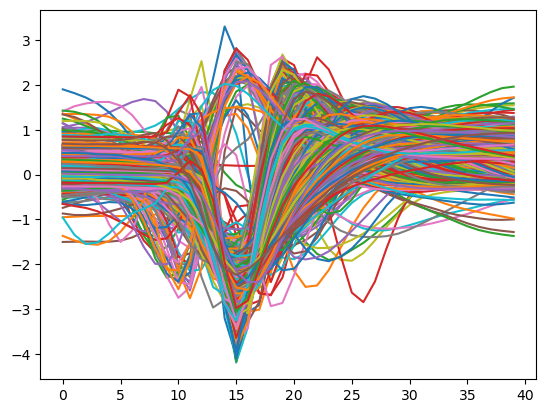

In [6]:
#plot zscore

from scipy.stats import zscore
for i in range(len(adf)):
    plt.plot(zscore(adf.iloc[i].avg_arrs))

In [7]:
# derived zscored waveforms
zwaves = []
for i in range(len(adf)):
    zwaves.append(zscore(adf.iloc[i].avg_arrs))
adf['zwaves'] = zwaves


In [8]:
# get amplitude and P2P

tdiff = []
amp = []

for i in range(len(zwaves)):
    maxi = np.argmax(zwaves[i])
    mini = np.argmin(zwaves[i])
    tdiff.append(abs(maxi-mini))
    amp.append(abs(np.max(zwaves[i])-np.min(zwaves[i])))
adf['amp'] = amp
adf['p2p'] = tdiff

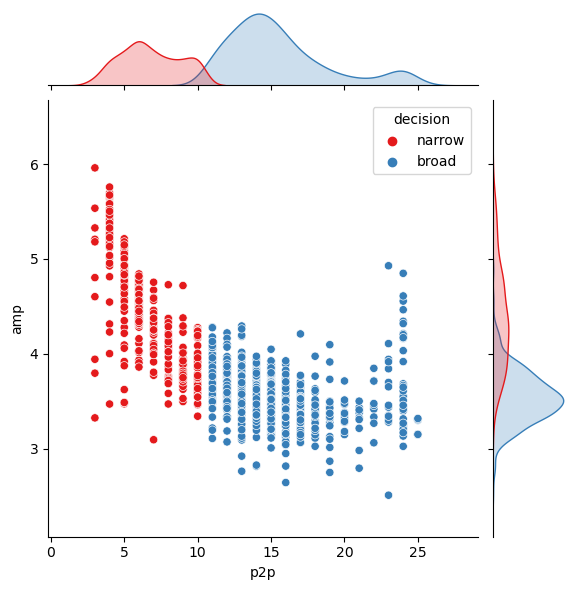

In [10]:
#plot amp X P2P
# a threshold is then applied to divided the units based on P2P of .35ms
import seaborn as sns


thresh = .35/1000*30000

dec = []
for i in range(len(adf)):
    if adf.iloc[i].p2p < thresh:
        dec.append('narrow')
    else:
        dec.append('broad')
adf['decision'] = dec   #store decision of broad vs narrow


#plot the data
#sns.scatterplot(x='p2p', y='amp', hue='decision', data=adf, palette='Set1')  #redundant with the joint plot
#plt.axvline(thresh)
sns.jointplot(x='p2p', y='amp', hue='decision', data=adf, palette='Set1')
#plt.axvline(thresh)

In [11]:
# not really necessary, it will make certain plotting/.computing easier later on

xs = []

for i in range(len(adf)):
    l = len(adf.iloc[i].zwaves)
    xs.append(list(range(1, l+1)))
adf['xs'] = [x for x in xs]  #could divide x by 30000, the SR, for true time units
adf

,clus_id,avg_arrs,birdid,hem,rec,zwaves,amp,p2p,decision,xs
0,2,"[-12.323978, -12.272786, -12.186848, -12.45004...",gn065,RH,ao1,"[-0.117148295, -0.11437419, -0.109717205, -0.1...",4.697133,6,narrow,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
1,5,"[19.599916, 19.33533, 19.3888, 19.420443, 19.6...",gn065,RH,ao1,"[0.58431, 0.5706354, 0.5733989, 0.57503426, 0....",3.279719,23,broad,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
2,43,"[-3.2078998, -3.1921732, -3.4520786, -3.252611...",gn065,RH,ao1,"[0.9882189, 0.9895464, 0.9676078, 0.9844448, 0...",2.947860,16,broad,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
3,61,"[-12.519182, -12.5942955, -12.321878, -13.2991...",gn065,RH,ao1,"[-0.06962755, -0.07080884, -0.06652462, -0.081...",4.523976,6,narrow,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
4,62,"[-2.790205, -2.7634804, -2.966775, -3.0904512,...",gn065,RH,ao1,"[0.2664566, 0.26792988, 0.25672287, 0.249905, ...",3.007238,15,broad,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
...,...,...,...,...,...,...,...,...,...,...
1101,212,"[-9.366799, -9.418162, -9.586836, -9.659364, -...",joe,LH,ao2,"[0.2894479, 0.2854925, 0.2725032, 0.2669179, 0...",3.468030,14,broad,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
1102,216,"[-1.999195, -2.2257001, -2.3162596, -2.4728122...",joe,LH,ao2,"[-0.15989523, -0.1680226, -0.17127201, -0.1768...",4.129970,11,broad,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
1103,217,"[6.4457045, 6.2908325, 6.289713, 6.297831, 6.2...",joe,LH,ao2,"[-0.17715558, -0.1847227, -0.18477741, -0.1843...",4.070316,12,broad,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
1104,220,"[-9.315411, -9.502773, -9.532934, -9.664317, -...",joe,LH,ao2,"[0.025312917, 0.016070465, 0.014582652, 0.0081...",3.382009,13,broad,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."


([<matplotlib.patches.Wedge at 0x129f3cc0110>,
 [Text(-0.9404255621387176, 0.5706134962267166, 'narrow'),
  Text(0.940425508714022, -0.5706135842757103, 'broad')],
 [Text(-0.5129593975302096, 0.3112437252145727, '32.6%'),
  Text(0.5129593683894665, -0.3112437732412965, '67.4%')])

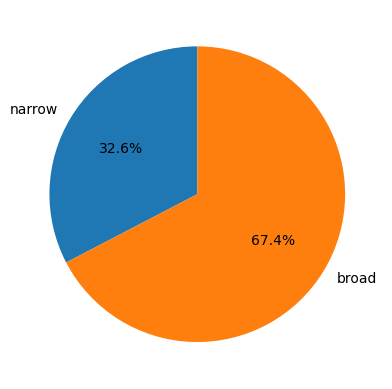

In [12]:
#pie chart to see frequency of narrow vs broad

from collections import Counter

counts = Counter(adf.decision)
labels = list(counts.keys())
sizes = list(counts.values())
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90)

In [ ]:
#save the df

#adf.to_pickle(r'Z:\regen_AudObj_analysis\withNormalizedFRs\analysis_files\SUA_decisions_ao.pkl')

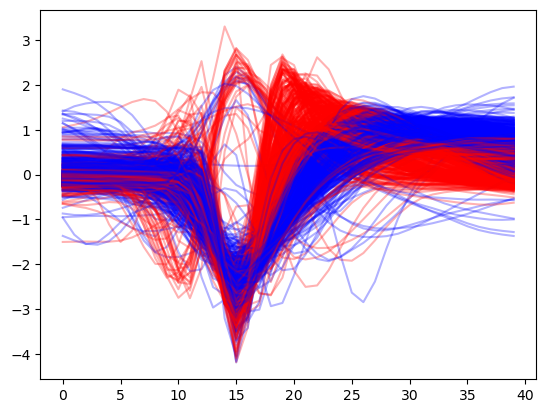

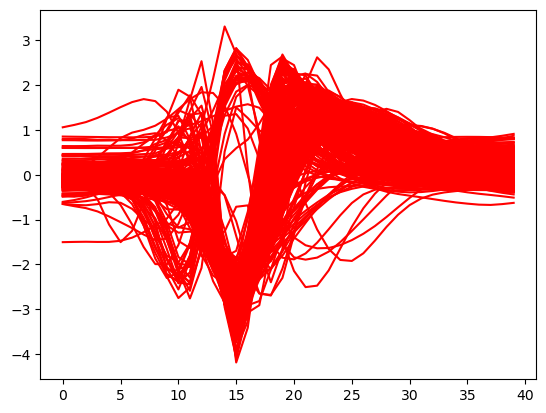

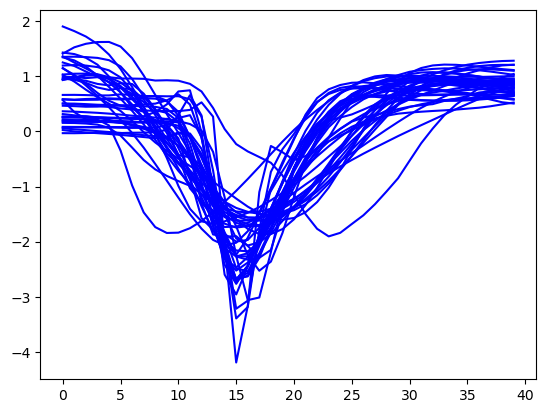

In [ ]:
#plot everything overlayed, note that sometimes spikes can be misaligned based on kilosort, extrcation, and shape...


for i in range(len(adf)):
    if adf.iloc[i].decision=='narrow':
        plt.plot(adf.iloc[i].zwaves, c='r', alpha=.3)
    else:
        plt.plot(adf.iloc[i].zwaves, c='b', alpha=.3)
plt.show()

arr = np.stack(adf[adf.decision=='narrow'].zwaves)
for i in range(len(arr)):
    plt.plot(arr[i], c='r')
plt.show()

arr = np.stack(adf[adf.decision=='broad'].zwaves)
for i in range(len(arr[i])):
    plt.plot(arr[i], c ='b')
plt.show()

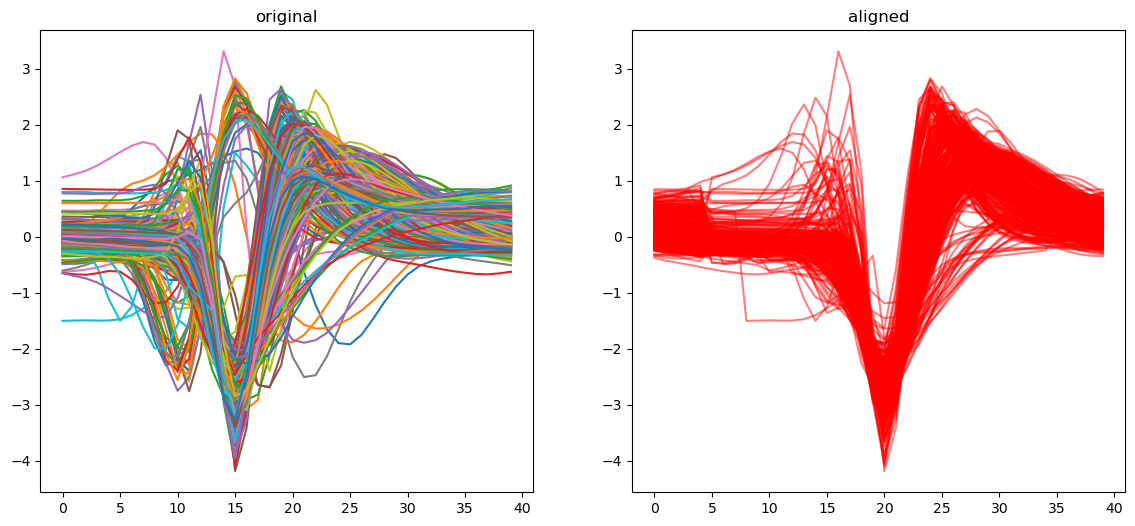

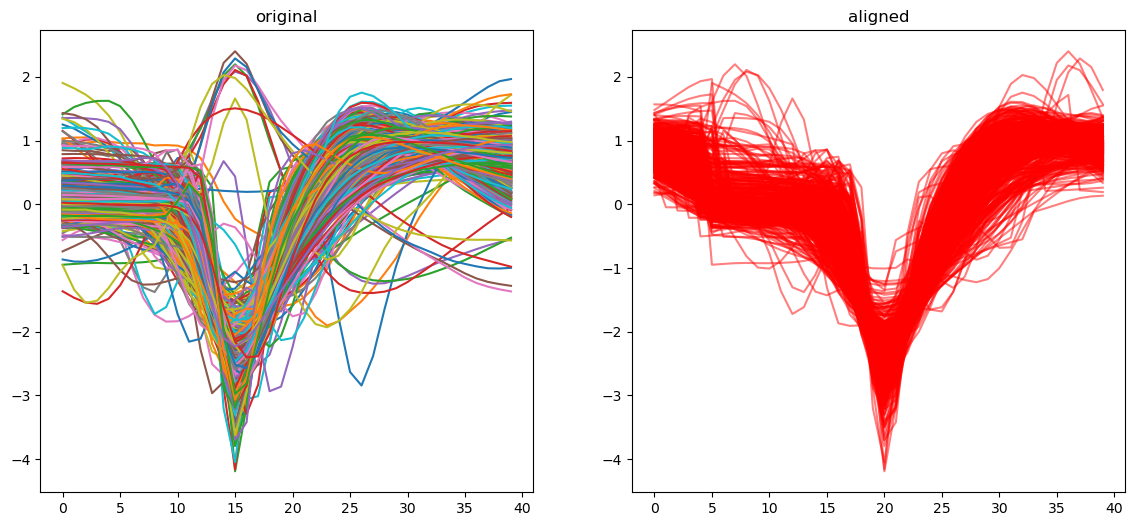

In [61]:
#example of spike-aligner usage

arr = np.stack(adf[adf.decision=='narrow'].zwaves)

aligned_narrow = spike_aligner(arr, align_reference = 'minimum', plot=True)

arr = np.stack(adf[adf.decision=='broad'].zwaves)

aligned_broad = spike_aligner(arr, align_reference = 'minimum', plot=True)



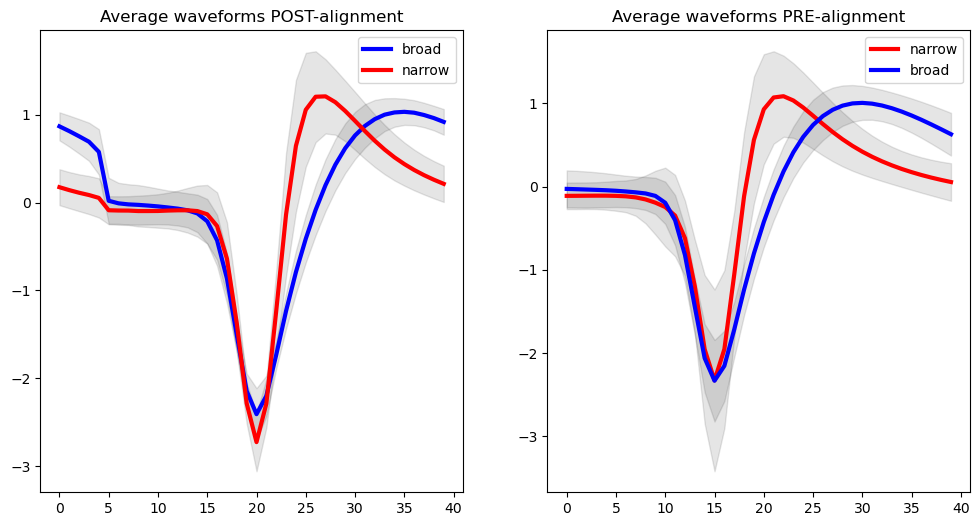

In [71]:
#averaged waveforms based on ALIGNED data


fig, axs = plt.subplots(1, 2, figsize=(12, 6))
m_broad = np.mean(aligned_broad, axis=0)
sd_broad = np.std(aligned_broad, axis=0)
axs[0].plot(m_broad, c='b', lw=3, label='broad')
xs = list(range(0, l))
axs[0].fill_between(xs, m_broad-sd_broad*.75, m_broad+sd_broad*.75, alpha=.1, color='k')

m_narrow = np.mean(aligned_narrow, axis=0)
sd_narrow = np.std(aligned_narrow, axis=0)
axs[0].plot(m_narrow, c='r', lw=3, label='narrow')
xs = list(range(0, l))
axs[0].fill_between(xs, m_narrow-sd_narrow*.75, m_narrow+sd_narrow*.75, alpha=.1, color='k')

axs[0].set_title('Average waveforms POST-alignment')
axs[0].legend()
################################################################

#plot the average waveforms for each both decisions/shapes, with error bands
# this is an example of how to use the adf to plot the NON-aligned waveforms
ptitle = 'Average waveforms PRE-alignment'

for d in adf.decision.unique():
    tmp = np.stack(adf[adf.decision==d].zwaves)
    #sns.lineplot(x='xs', y='zwaves', hue='clus_id', data=adf[adf.decision==d])
    if d == 'narrow':
        axs[1].plot(np.mean(tmp, axis=0), lw=3, c='r', label='narrow')
    else:
        axs[1].plot(np.mean(tmp, axis=0), lw=3, c='b', label='broad')
    mu = np.mean(tmp, axis=0)
    sd = np.std(tmp, axis=0)
    xs = list(range(0, l))
    axs[1].fill_between(xs, mu-sd*.75, mu+sd*.75, alpha=.1, color='k')
axs[1].set_title(ptitle)
axs[1].legend()

In [ ]:
#optional, run PCA on waveforms

from sklearn.decomposition import PCA
X = np.stack(adf.avg_arrs)

pca = PCA(n_components=3)
tra = pca.fit_transform(zscore(X, axis=0))

pcdf = pd.DataFrame({'PC1':tra[:,0], 'PC2':tra[:,1], 'PC3':tra[:,2], 'decs':adf.decision})
sns.scatterplot(x='PC2', y='PC3',hue='decs', data=pcdf)